# **Decision Tree Model: Box Office Revenue Prediction**
### Ciaran O' Toole - C00297672
##### A portfolio produced as part of the Data Science & Machine Learning 1 Module in SE603, Bachelor of Science (Honours) Software Development at SETU

This notebook marks the first modelling stage of my portfolio, focusing on building, training, and evaluating a baseline **Decision Tree** model using my currated and verified dataset of 902 movies prepared in `Datasetcleansing.ipynb` and stored in `movies.csv`. The objective is to investigate whether a movie's production budget alone can accurately predict its worldwide box office revenue.


### **Step 1 - Load My Cleaned Data & Exploratory Overview (EDA)**

First, I load the verified dataset `movies.csv` containing the 902 movie records. Because Decision Trees capture non-linear relationships rather than assuming a constant linear slope. My goal here is to inspect the summary statistics and plot the raw distribution of **budget** against **revenue** without forcing a linear best-fit line.

             budget       revenue
count  9.020000e+02  9.020000e+02
mean   8.452772e+07  3.589842e+08
std    8.097168e+07  3.916373e+08
min    3.500000e+04  5.524000e+04
25%    1.900000e+07  7.750090e+07
50%    6.000000e+07  2.398537e+08
75%    1.385000e+08  5.047626e+08
max    6.588000e+08  2.942650e+09


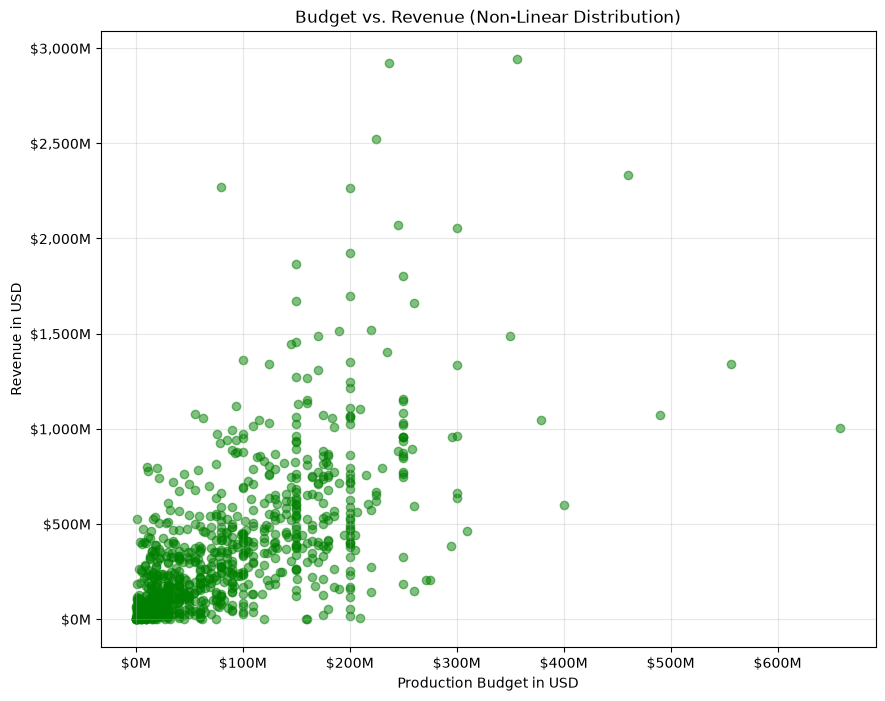

In [3]:
import pandas as pand
import numpy as np
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plot

# load my dataset
movies = pand.read_csv("movies.csv")

print(movies[["budget", "revenue"]].describe())

# displays the x and y nums as Millions rather than raw integers
numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")

plot.figure(figsize=(10, 8))
plot.scatter(movies["budget"], movies["revenue"], alpha=0.5, color="green")

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.xlabel("Production Budget in USD")
plot.ylabel("Revenue in USD")
plot.title("Budget vs. Revenue (Non-Linear Distribution)")
plot.grid(True, alpha=0.3)
plot.show()

### **Step 2 - Data Preprocessing**

Before training the model, I prepare the dataset using the exact same split as my Linear Regression baseline, this keeps it fair across all models:

Only **budget** and **revenue** are needed. I make sure to stay consistent and split the data into an 80/20 training and testing split using `random_state=42` so all models are evaluated on the exact same 181 unseen test movies. Unlike Linear Regression, Decision Trees split data using threshold inequalities (e.g., `budget <= $50M`), which are invariant to monotonic scaling. Keeping **budget** in raw USD preserves identical splits while making the decision rules readable.

In [4]:
from sklearn.model_selection import train_test_split

x = movies[["budget"]]
y = movies["revenue"]

# create the training and test split in an 80/20 ratio like before
xtrainingset, xtestingset, ytrainingset, ytestingset = train_test_split( x, y, test_size=0.2, random_state=42)

print(f"Training set: {len(xtrainingset)}")
print(f"Testing set: {len(xtestingset)}")

Training set: 721
Testing set: 181


### **Step 3 - Model Training**

Now that the training and testing sets are prepared, I initialise scikit-learn's `DecisionTreeRegressor` and fit it on the training data. I set `max_depth=3` and `random_state=42` to prevent the tree from memorising individual training movies and overfitting the data. If i did not include a max depth the tree would just for every movie keep splitting which would not be ideal. We search from a depth of 1-9 to see which fits the best, doing this allows us to better fit and account for the model just fitting to noise, and we also do not want to underfit or overfit the model

In [9]:
from sklearn.tree import DecisionTreeRegressor
for depth in range(1, 10):
  test = DecisionTreeRegressor(max_depth=depth, random_state=42)
  test.fit(xtrainingset, ytrainingset)

  trainR2 = test.score(xtrainingset, ytrainingset)
  testR2 = test.score(xtestingset, ytestingset)

  print(f"| Train R2: {trainR2:.4f} | Test R2: {testR2:.4f} |")

| Train R2: 0.3163 | Test R2: 0.3703 |
| Train R2: 0.4316 | Test R2: 0.3719 |
| Train R2: 0.4630 | Test R2: 0.4193 |
| Train R2: 0.5155 | Test R2: 0.3244 |
| Train R2: 0.5587 | Test R2: 0.1653 |
| Train R2: 0.5885 | Test R2: 0.1533 |
| Train R2: 0.6062 | Test R2: 0.0970 |
| Train R2: 0.6190 | Test R2: 0.0447 |
| Train R2: 0.6233 | Test R2: 0.0219 |


As we can see from above, a `max_depth=3` of 3 is the sweet spot for the model we are training.

In [10]:

# sets up the model with a controlled max_depth to prevent overfitting
model = DecisionTreeRegressor(max_depth=3, random_state=42)
model.fit(xtrainingset, ytrainingset)

print(f"Tree Depth: {model.get_depth()}")
print(f"Number of Leaf Nodes: {model.get_n_leaves()}")

Tree Depth: 3
Number of Leaf Nodes: 8


### **Step 4 - Model Evaluation & Testing**

I evaluate & test the trained Decision Tree on the 181 test movies **xtestingset** using the same three regression metrics of **MAE**, **RMSE**, and an **$R^2$ Score** and compare actual vs. predicted revenue for a sample of test movies.

In [12]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# use the trained model to predict revenue for the test set
ypredictions = model.predict(xtestingset)

# evaluate the accuracy metrics
rmse = root_mean_squared_error(ytestingset, ypredictions)
r2 = r2_score(ytestingset, ypredictions)
mae = mean_absolute_error(ytestingset, ypredictions)
# output accuracy metrics
print(f"RMSE: ${rmse:,.2f}")
print(f"MAE: ${mae:,.2f}")
print(f"R2: {r2:.4f}")
print("\n")

# calculate how far off the model is from the actual values
differences = ytestingset - ypredictions

# make a table and show the predicted vs actual
comparison = pand.DataFrame({
    "Actual Revenue": [f"${m:,.0f}" for m in ytestingset],
    "Predicted Revenue": [f"${m:,.0f}" for m in ypredictions],
    "Difference": [f"${m:,.0f}" for m in differences]
})

print(comparison.head(50))

RMSE: $278,078,024.22
MAE: $190,376,556.96
R2: 0.4193


    Actual Revenue Predicted Revenue     Difference
0   $1,338,073,645    $1,500,128,594  $-162,054,948
1      $72,900,246      $403,694,095  $-330,793,849
2       $3,386,250      $258,325,036  $-254,938,786
3     $499,256,445      $258,325,036   $240,931,409
4      $39,251,917      $258,325,036  $-219,073,119
5      $71,981,823       $69,382,374     $2,599,449
6     $226,497,209      $479,025,910  $-252,528,701
7     $775,398,007      $146,135,863   $629,262,144
8      $93,722,164      $146,135,863   $-52,413,699
9     $772,775,278      $643,280,085   $129,495,193
10    $397,378,150      $643,280,085  $-245,901,935
11    $153,000,000      $258,325,036  $-105,325,036
12    $566,652,812      $643,280,085   $-76,627,273
13    $475,000,000      $643,280,085  $-168,280,085
14     $33,754,967       $69,382,374   $-35,627,407
15    $340,955,294      $146,135,863   $194,819,431
16    $877,244,782      $479,025,910   $398,218,872
17     $

### **Step 5 - Visualising Test Set Predictions & Splits**

Now that I have evaluated the accuracy scores, I graph the Decision Tree's prediction curve across a sorted budget range against the actual box office revenues from the testing set, followed by a diagram of the learned decision thresholds.

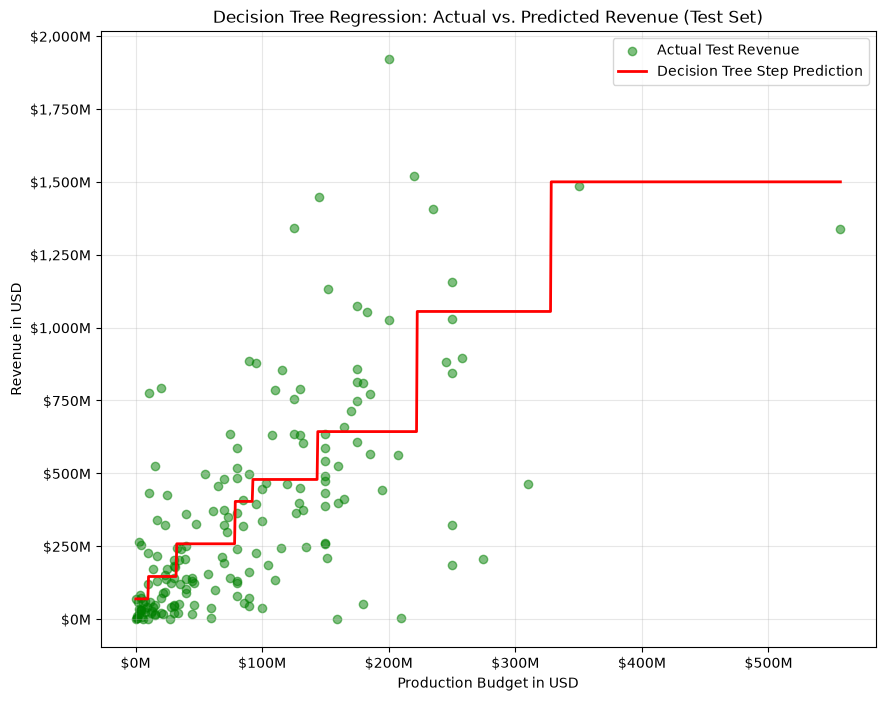

In [31]:
# find the lowest and highest budgets in the test set
minbudg = xtestingset["budget"].min()
maxbudg = xtestingset["budget"].max()

# make 500 evenly spaced budget numbers between the lowest and highest
range = np.linspace(minbudg, maxbudg, 1000)

# put those numbers into a table (DataFrame) so the model can predict on them
budgetgrid = pand.DataFrame({"budget": range})
gridpredictions = model.predict(budgetgrid)
gridpredictions = model.predict(budgetgrid)

plot.figure(figsize=(10, 8))
plot.scatter(xtestingset["budget"], ytestingset, alpha=0.5, color="green", label="Actual Test Revenue")
plot.plot(budgetgrid["budget"], gridpredictions, color="red", linewidth=2, label="Decision Tree Step Prediction")
plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.title("Decision Tree Regression: Actual vs. Predicted Revenue (Test Set)")
plot.xlabel("Production Budget in USD")
plot.ylabel("Revenue in USD")
plot.legend()
plot.grid(True, alpha=0.3)
plot.show()
del range

Next, I visualise the internal structure of the trained Decision Tree (`max_depth=3`) to inspect the budget thresholds the model learned from the training movie set.

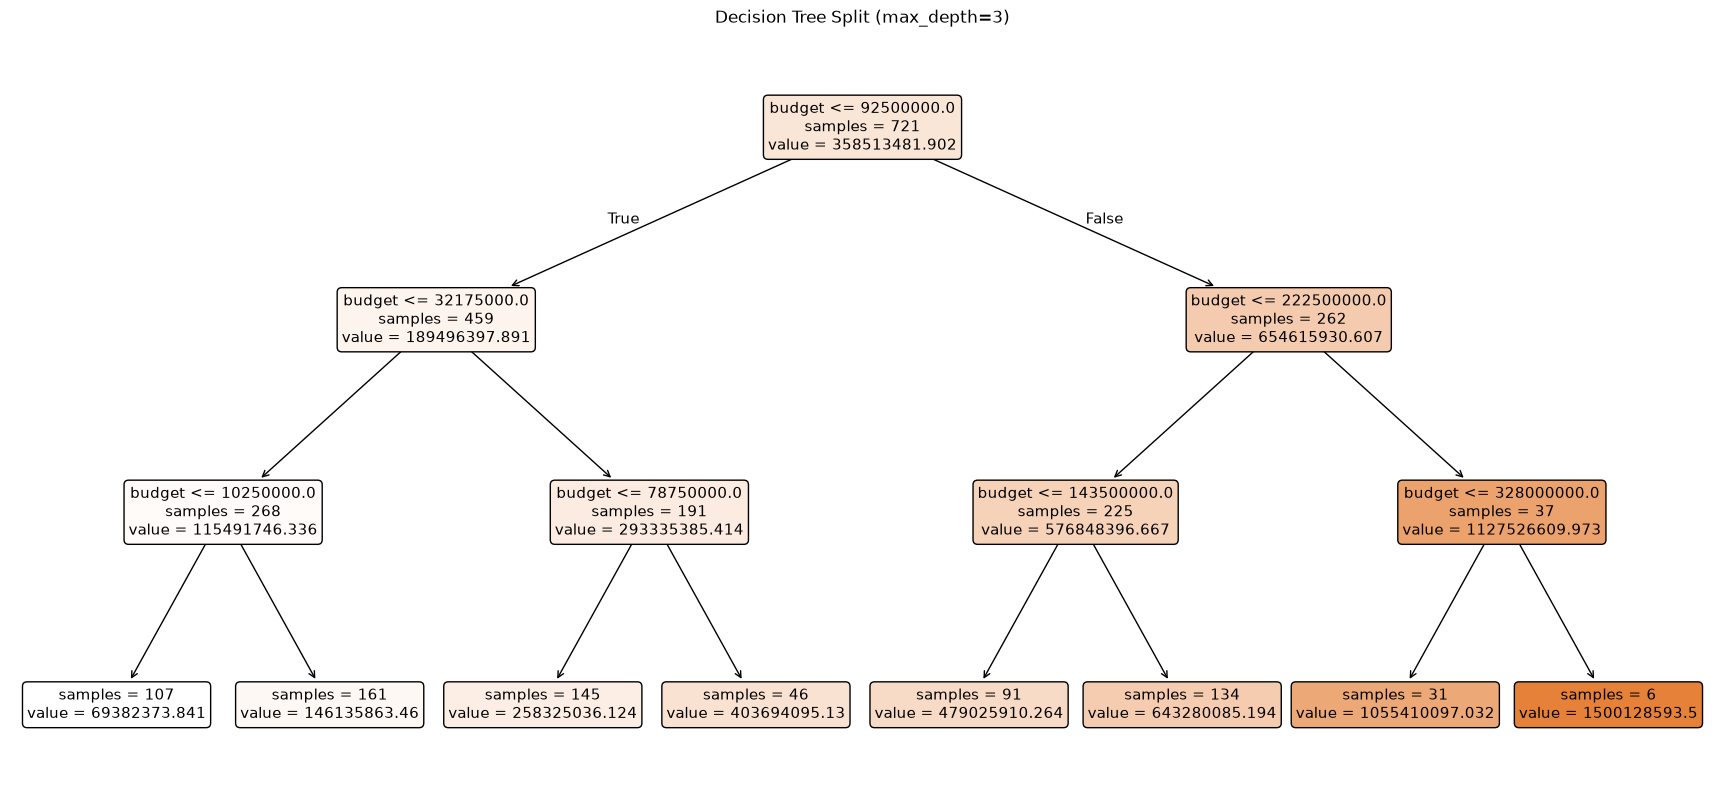

In [32]:
from sklearn.tree import plot_tree

plot.figure(figsize=(22, 10))
plot_tree(
    model,
    feature_names=["budget"],
    filled=True,
    impurity=False,
    rounded=True,
    fontsize=11,
)
plot.title("Decision Tree Split (max_depth=3)")
plot.show()

### **Step 6 - Export Data for the Website**

Now that I am finished with analysing Decision Trees, I need to export this model's outputs to a json for my portfolio website. To do this I generate predictions for all 902 movies, gather the model parameters and accuracy metrics (`MaxDepth`, `Leaves`, `MAE`, `RMSE`, `R2`), and save everything into `decisiontree.json` so the website's search feature can query and compare results dynamically.

In [33]:
import json

# predict revenue for all 902 movies using raw budgets
everyprediction = model.predict(movies[["budget"]])
allmovies = []

for i in range(len(movies)):
  iD = movies.iloc[i]
  pred = float(everyprediction[i])
  actual = float(iD["revenue"])
  allmovies.append({
      "title": str(iD["title"]),
      "split": "Testing" if iD.name in xtestingset.index else "Training",
      "budget": round(float(iD["budget"]), 0),
      "actualrevenue": round(actual, 0),
      "predictedrevenue": round(pred, 0),
      "difference": round(actual - pred, 0),
  })

export = {
    "Model": "Decision Tree",
    "MAE": round(float(mae), 2),
    "RMSE": round(float(rmse), 2),
    "R2": round(float(r2), 4),
    "R2_percentage": round(float(r2) * 100, 1),
    "MaxDepth": int(model.get_depth()),
    "Leaves": int(model.get_n_leaves()),
    "movies": allmovies,
}

with open("decisiontree.json", "w") as file:
  json.dump(export, file, indent=4)


### **Conclusion of Decision Tree Regression**

Overall, the Decision Tree model proved **weaker** than the Linear Regression baseline when predicting box office revenue on unseen movies. Decision Trees are typically **stronger** at capturing non-linear groupings without forcing a single rigid slope across all films, however, splitting a continuous variable into a small set of flat level brackets means every movie within the same budget tier receives the exact same predicted revenue—losing the smooth upward scaling that Linear Regression captures as budgets grow.

With both single-feature baselines complete, I will now move on to the next model in the portfolio to explore stronger predictive approaches.